# 3. Combined portfolio results

Combining signals can help when they identify different stocks. This can be useful under a long-only constraint, where the portfolio cannot take a negative stock position. The test compares two blends. One uses original DMD with the inflation signal. The other uses adjusted DMD with the same inflation signal.

The combination uses an equal-weight rule and three ridge rules with different half-lives. The equal prior gives both signals the same starting coefficient. The rules with shorter half-lives use stronger penalties to limit the effect of noisy recent data. The rules with longer half-lives use weaker penalties and can adjust more gradually as the data accumulate. Each blend gives more weight to candidate rules with better past active results. Notebook 1 gives the fit, normalization, and model update.

In [1]:
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

DATA = Path('dataset')
returns = pd.read_parquet(DATA / 'regular_dmd_returns.parquet')
returns['date'] = pd.to_datetime(returns['date'])
returns['return_date'] = pd.to_datetime(returns['return_date'])
returns = returns.sort_values('return_date')
SIGNALS = ['dmd', 'adjusted', 'inflation_beta']
BLENDS = ['bma_original', 'bma_adjusted']
VARIANTS = {'long_short': 'Long-short', 'long_only': 'Long-only'}
LABELS = {
    'dmd': 'Original DMD',
    'adjusted': 'DMD adjusted for momentum and reversal',
    'inflation_beta': 'Betting Against Inflation Beta',
    'bma_original': 'Bayesian blend with original DMD',
    'bma_adjusted': 'Bayesian blend with adjusted DMD',
}
COLORS = dict(zip(LABELS, ['#2264a7', '#df781e', '#259145', '#2264a7', '#df781e']))

def growth(group, relative):
    # Use log returns to build a compound return path.
    log_return = np.log1p(group['portfolio_return'].to_numpy())
    if relative:
        log_return -= np.log1p(group['benchmark_return'].to_numpy())
    return np.r_[0.0, log_return.cumsum()]

def max_drawdown(path):
    # Start at wealth of one, before the first holding return.
    return np.expm1(path - np.maximum.accumulate(path)).min()

def chart(models, title, relative):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, (variant, label) in zip(axes, VARIANTS.items()):
        for model in models:
            group = returns.loc[(returns['portfolio'] == model) & (returns['variant'] == variant)]
            ax.plot(group['return_date'], np.expm1(growth(group, relative)[1:]),
                    label=LABELS[model], color=COLORS[model])
        if not relative:
            benchmark = np.expm1(np.log1p(group['benchmark_return']).cumsum())
            ax.plot(group['return_date'], benchmark, '--', color='0.35', label='Benchmark')
        ax.set_title(label)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(axis='y', alpha=.2)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('Cumulative benchmark-relative return' if relative else 'Cumulative total return')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=min(len(labels), 2), frameon=False)
    fig.suptitle(title)
    fig.tight_layout(rect=(0, .12, 1, .92))
    plt.show()


## 3.1 Compare active and total performance

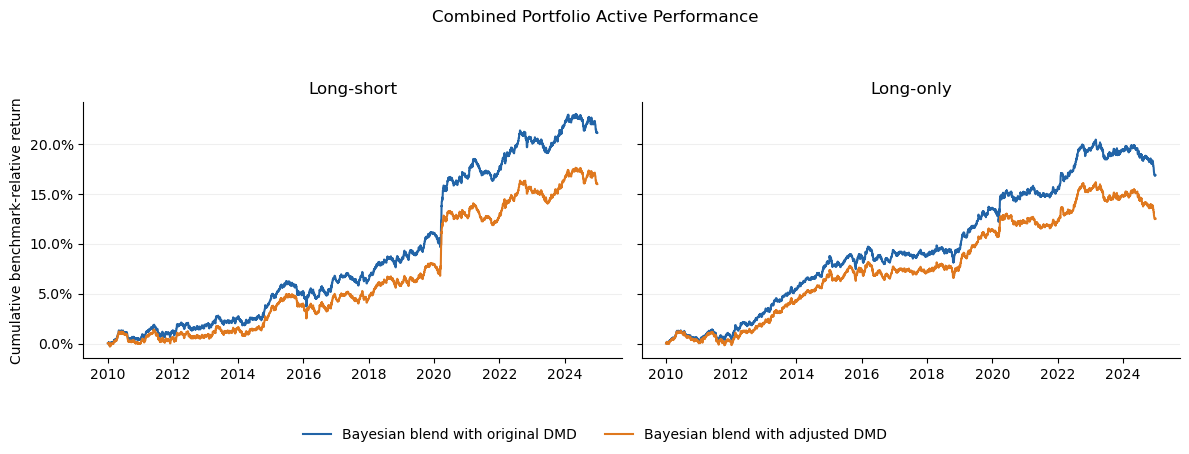

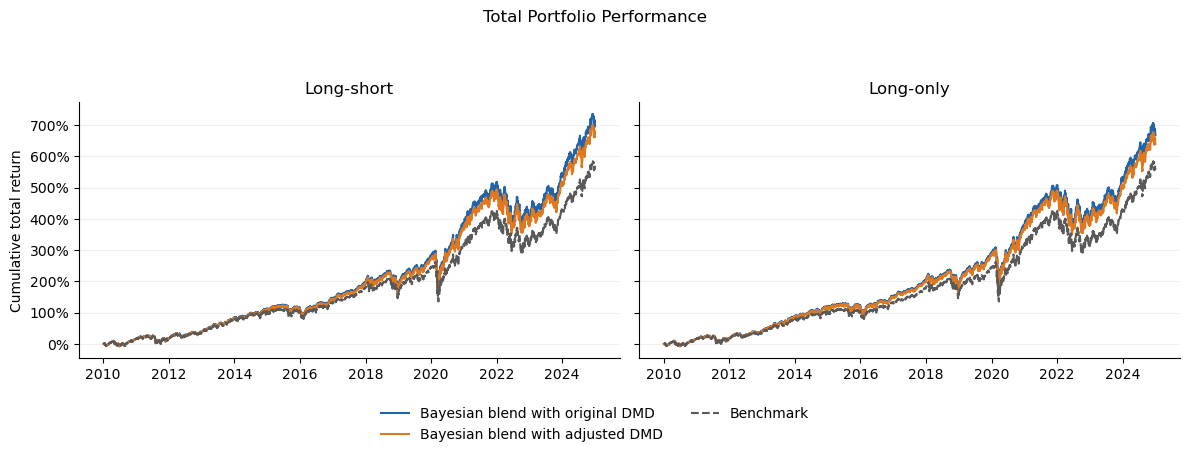

In [2]:
chart(BLENDS, 'Combined Portfolio Active Performance', True)
chart(BLENDS, 'Total Portfolio Performance', False)

## 3.2 Compare active results

Annualized active return is 252 times the mean daily difference between portfolio and benchmark returns. Realized tracking error is the standard deviation of this difference, annualized. The information ratio divides the first value by the second. Predicted tracking error is the mean of the daily annualized risk forecasts.

In [3]:
risk_free = pd.read_csv(DATA / 'daily_risk_free.csv', parse_dates=['return_date'])
sample = returns.merge(risk_free, on='return_date', validate='many_to_one', how='left')
assert sample['risk_free_return'].notna().all()

active_rows = []
total_rows = []
for model in BLENDS:
    for variant, label in VARIANTS.items():
        group = sample.loc[(sample['portfolio'] == model) & (sample['variant'] == variant)]
        active = group['active_return']
        realized_te = np.sqrt(252) * active.std(ddof=1)
        relative_path = growth(group, True)
        excess = group['portfolio_return'] - group['risk_free_return']
        key = {'Portfolio': LABELS[model], 'Constraint': label}
        active_rows.append({**key, 'Annualized active return': 252 * active.mean(),
            'Information ratio': 252 * active.mean() / realized_te,
            'Predicted tracking error': group['forecast_tracking_error'].mean(),
            'Realized tracking error': realized_te,
            'Cumulative relative return': np.expm1(relative_path[-1]),
            'Maximum relative drawdown': max_drawdown(relative_path)})
        total_path = growth(group, False)
        total_rows.append({**key, 'Total Sharpe ratio': np.sqrt(252) * excess.mean() / excess.std(ddof=1),
            'Total return CAGR': np.expm1(total_path[-1] * 252 / len(group)),
            'Maximum total drawdown': max_drawdown(total_path),
            'Annualized total volatility': np.sqrt(252) * group['portfolio_return'].std(ddof=1)})

def formatted(rows):
    table = pd.DataFrame(rows).set_index(['Portfolio', 'Constraint'])
    return table.style.format({c: '{:.2f}' if 'ratio' in c else '{:.2%}' for c in table})

display(formatted(active_rows))

## 3.3 Compare total results

Total Sharpe uses daily excess returns over the risk-free rate from the [Kenneth R. French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html). Total return is a compound annual growth rate. Drawdown measures the largest drop in wealth from its previous high.

In [4]:
benchmark = sample.loc[(sample['portfolio'] == BLENDS[0]) & (sample['variant'] == 'long_short')]
bench_return = benchmark['benchmark_return']
excess = bench_return - benchmark['risk_free_return']
bench_path = np.r_[0.0, np.log1p(bench_return).cumsum()]
total_rows.append({'Portfolio': 'Benchmark', 'Constraint': '—',
    'Total Sharpe ratio': np.sqrt(252) * excess.mean() / excess.std(ddof=1),
    'Total return CAGR': np.expm1(bench_path[-1] * 252 / len(benchmark)),
    'Maximum total drawdown': max_drawdown(bench_path),
    'Annualized total volatility': np.sqrt(252) * bench_return.std(ddof=1)})
display(formatted(total_rows))

## 3.4 Reference charts for signal and model weights

These charts use the Barra-adjusted reference run. They show how the same combination rules work when the DMD input uses the Barra style adjustment. The sf-quant comparison above uses a different adjusted DMD input. Its saved daily model weights are unavailable here.

One coefficient unit equals 0.00001, the common ridge prior. The chart of model weights shows how the reference run divides the forecast among four rules.

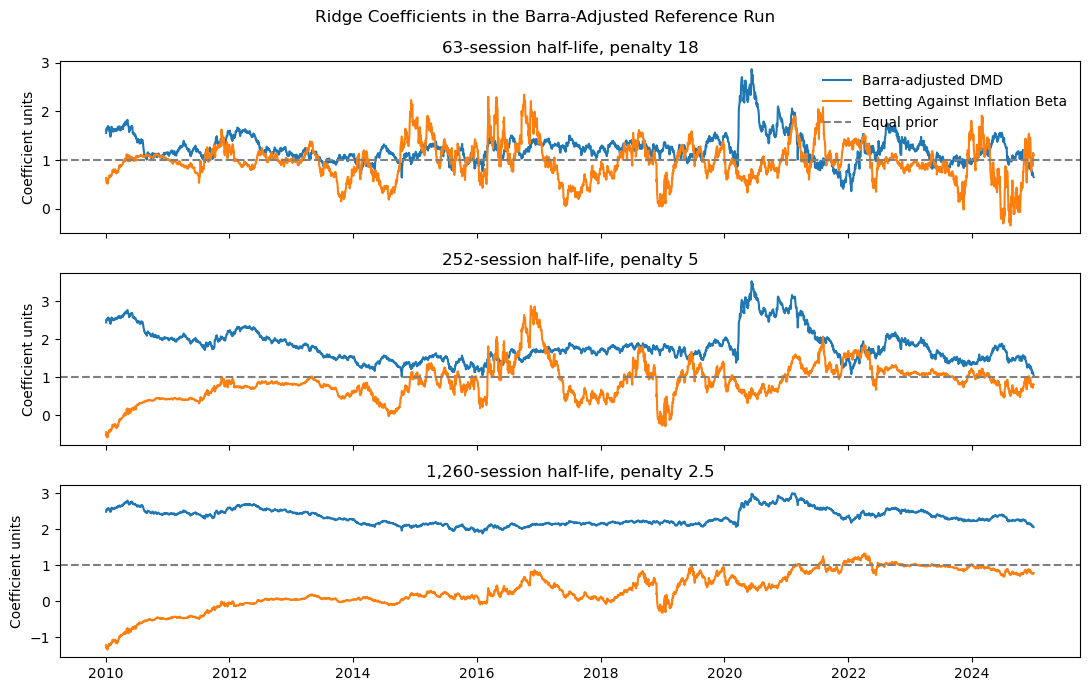

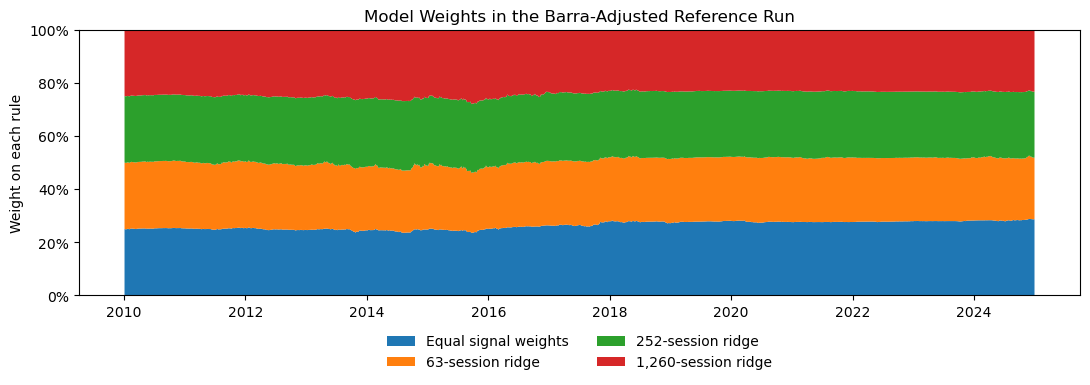

In [5]:
coefficients = pd.read_parquet(DATA / 'barra_reference_coefficients.parquet').sort_values('date')
rules = {
    'ridge_63_p18': '63-session half-life, penalty 18',
    'ridge_252_p5': '252-session half-life, penalty 5',
    'ridge_1260_p2.5': '1,260-session half-life, penalty 2.5',
}
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, (rule, label) in zip(axes, rules.items()):
    group = coefficients.loc[coefficients['method'] == rule]
    dates = pd.to_datetime(group['date'])
    ax.plot(dates, group['dmd'] / 1e-5, label='Barra-adjusted DMD')
    ax.plot(dates, group['inflation_beta'] / 1e-5, label='Betting Against Inflation Beta')
    ax.axhline(1, color='0.5', linestyle='--', label='Equal prior')
    ax.set_title(label)
    ax.set_ylabel('Coefficient units')
axes[0].legend(frameon=False)
fig.suptitle('Ridge Coefficients in the Barra-Adjusted Reference Run')
fig.tight_layout()
plt.show()

weights = pd.read_parquet(DATA / 'barra_reference_model_weights.parquet')
weights = weights.loc[weights['variant'] == 'active'].sort_values('date')
fields = ['equal_weight', *rules]
np.testing.assert_allclose(weights[fields].sum(axis=1), 1)
fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(pd.to_datetime(weights['date']), *[weights[field] for field in fields],
             labels=['Equal signal weights', '63-session ridge', '252-session ridge', '1,260-session ridge'])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Model Weights in the Barra-Adjusted Reference Run', ylabel='Weight on each rule', ylim=(0, 1))
ax.legend(loc='upper center', ncol=2, bbox_to_anchor=(.5, -.10), frameon=False)
fig.tight_layout()
plt.show()

## 3.5 Interpret the blend

Compared with standalone original DMD, the Bayesian blend had a higher long-only information ratio before costs, 0.89 versus 0.74. The long-short ratio was 1.01 versus 1.00. The comparison changes both the signals and the weighting rule. It cannot isolate the contribution of dynamic weighting over a fixed 50/50 mix. The rationale for dynamic weighting is that signal strength can change over time. Notebook 4 tests how trading costs change the result.